# 12 - Wrapping any forecaster: CQR bands, a pre-trained stand-in and the benchmark table

> "A vendor pitches a pre-trained foundation model - zero setup, any series. Our data
> scientist wants gradient boosting. Facilities wants to keep same hour last week. Who gets
> the budget?" - Kestrel head of operations

Three contenders, and they are three different kinds of object: a rule with no parameters,
a model fitted to our own meter, and a model fitted to somebody else's meters. "Which one is
most accurate" is not the question that decides a budget. The sharper question is this: on
the honest walk-forward protocol of notebook 11, separately for each family and each
horizon, which contender gives the best point forecast AND the best calibrated band - and
is the margin worth what the contender costs to run? The move that makes the comparison
fair is to take the band away from the contenders. We wrap every one of them in the same
conformal step, so every band carries the same 90% promise, and what remains to compare is
accuracy and width, priced together by the interval score.

**What you will learn**

- why CQR (notebook 05) can wrap any forecaster that emits quantiles, and how to run it per
  horizon inside walk-forward blocks
- how far raw quantile bands miss their nominal 90% on time series - in both directions -
  and what the conformal step does about it
- what a pre-trained (foundation) forecaster is, the interface contract it must meet to be
  wrapped, and a transparent stand-in you can run offline
- how pre-training overlap flatters a zero-shot score, committed live
- how to build and read the benchmark table - family x horizon x method with MAE, coverage,
  width and interval score - and how to turn it into a replace-or-keep decision

**Where we are in the series.** Notebook 11 built the honest backtest (walk-forward blocks,
the h-row purge, the leakage test, the interval score) and ended with a benchmark-table
template whose model row was a GBM inside notebook 02's absolute-residual band. This
notebook fills that template with the upgrades: CQR from notebook 05, a pre-trained
stand-in, and an ensemble. It leans on notebook 01 (the training-residual sin), notebook 05
(CQR), notebook 08 (quantile crossing) and notebook 09 (exchangeable at which level).
Notebook 13 asks next what frozen sensors do to every number in the table.

## 1. The wrapper idea

CQR in four sentences, as notebook 05 built it. Fit two quantile models, one for the 5th
and one for the 95th percentile, and treat the gap between them as a candidate 90% band. On
a calibration set the models never trained on, score every row by how far outside that
band the truth landed: $\max(lo - y,\ y - hi)$, negative when the truth was safely inside.
Take the corrected quantile $\hat{q}$ of those scores (notebook 02) and move both edges out
by it - or in, when $\hat{q}$ comes out negative.

The point for the project is in what that recipe never asks. It never asks how the two
quantiles were produced. Boosting, a deep network, a foundation model somebody else trained
on a data centre's worth of series, a rule read off a table: CQR wraps any of them, because
the guarantee lives in the calibration step, not in the model. By the time calibration
runs, the forecaster is a frozen function, and the score simply records how wrong its
quantiles were on rows it never saw.

Why raw quantile heads need the wrapper at all: they are fitted on training data, so their
opinion of their own spread inherits notebook 01's training-residual sin, one step removed
(field guide §2). A pinball loss minimized on the training rows produces quantiles that are
honest about the training rows. And on time series the world also moves between fit and
use. Some foundation-model documentation says plainly that its quantile outputs are not
calibrated; read that as a request for a calibration step, not as a footnote.

**Why it works, and where it bends.** In words: if the calibration scores and the score of
the next test row are exchangeable - nobody could tell which one came last - then the test
score is equally likely to land at any rank among them, so it exceeds the corrected
quantile at most 10% of the time; and "the score is at most $\hat{q}$" is literally the
same statement as "the truth is inside the widened band". In symbols:

$$s = \max\big(\hat{q}_{lo}(x) - y,\; y - \hat{q}_{hi}(x)\big), \qquad
s \le \hat{q} \iff y \in \big[\hat{q}_{lo}(x) - \hat{q},\; \hat{q}_{hi}(x) + \hat{q}\big]$$

where $x$ is everything known at the forecast origin, $\hat{q}_{lo}(x)$ and
$\hat{q}_{hi}(x)$ are the forecaster's raw 5th and 95th percentile forecasts, $y$ is the
value that actually arrived and $\hat{q}$ is the corrected quantile of the calibration
scores. Nothing in that chain mentions the model. What it does need - exchangeability - is
only approximately true on a time series (notebooks 09 and 10): a calibration window four
weeks old and the block that follows it are similar, not interchangeable. The walk-forward
recipe of notebook 11 keeps the gap short - recalibrate before every block, on the most
recent window whose targets are already known - and notebook 15 handles the weeks when even
a short gap is too long.

One more subtlety, which will save us code later: notebook 02's absolute-residual band is
CQR applied to a forecaster whose raw band has zero width. Set both $\hat{q}_{lo}$ and
$\hat{q}_{hi}$ equal to the point forecast and the score becomes $|y - \text{point}|$, the
band becomes point plus or minus $\hat{q}$. The "best simple rule + absolute-residual
band" row of the benchmark table will run through exactly the same function as the boosted
models.

In [1]:
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits                 # installed with scikit-learn

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
RANDOM_SEED = 20260707
ALPHA = 0.10   # the project's 90% band

# Series palette: blue = data, green = covered/healthy, amber = calibration/warning,
# red = missed/fault/naive, gray = reference, purple = alternative method.
BLUE, GREEN, AMBER, RED, GRAY, PURPLE = (
    "#2563EB", "#059669", "#F59E0B", "#DC2626", "#6B7280", "#7C3AED",
)
NOTEBOOK_START = time.perf_counter()   # the runtime budget is part of the protocol

# This notebook fits about 100 small models. HistGradientBoosting spreads each fit over
# every CPU core; on tables this small the coordination costs more than it saves, and on a
# busy laptop it can make every fit several times slower. One thread is plenty here, and
# it does not change a single prediction. (Keep the returned object: it holds the limit.)
THREAD_LIMIT = threadpool_limits(1, user_api="openmp")

The next two cells are the shared Part II code, copied verbatim. Two simulators are new to
this notebook: `simulate_building_portfolio` and `simulate_vm_fleet` produce sites and
machines that obey the same physics as our two series but with their own sizes,
occupancies, burst rates and seeds. Read their docstrings - they are the pre-training corpus
of section 3. Everything else (`make_direct_table`, `quantile_gbm`, `walk_forward_blocks`,
the metrics) is exactly what notebook 11 used, so the numbers below are comparable with it.

In [2]:
def simulate_building_load(n_days, seed, start="2016-01-01", base_kwh=120.0,
                           occupied_kwh=180.0, hvac_kwh_per_deg=6.0, noise_frac=0.06,
                           shift_day=None, shift_frac=0.0):
    """Simulate an hourly electricity meter for one Kestrel office building.

    What the simulator bakes in (and what later notebooks test against):
    - A daily occupancy profile: busy 08:00-18:00 on weekdays, quiet nights and weekends.
      That is why 'same hour yesterday' and 'same hour last week' are strong baselines.
    - Heating and cooling: load rises when the outdoor temperature leaves a comfort zone,
      and the temperature follows the seasons, so summer and winter behave differently.
    - Noise that is autocorrelated (a busy morning tends to stay busy) and larger when the
      building is occupied. Residuals are neither independent nor equal-sized.
    - Optional regime change: from day `shift_day` on, the load level is multiplied by
      (1 + shift_frac) - a new tenant, a retrofit. Notebook 15 uses it to break calibration.

    Returns a DataFrame indexed by hourly timestamp with columns `load_kwh` and `temp_c`.
    """
    rng = np.random.default_rng(seed)
    idx = pd.date_range(start, periods=24 * n_days, freq="h")
    n = len(idx)
    hour = idx.hour.to_numpy()
    dow = idx.dayofweek.to_numpy()
    doy = idx.dayofyear.to_numpy()

    # Weather: seasons + a daily cycle + persistent anomalies (a cold week stays cold).
    anomaly = np.zeros(n)
    shocks = rng.normal(0.0, 0.6, size=n)
    for i in range(1, n):
        anomaly[i] = 0.97 * anomaly[i - 1] + shocks[i]
    temp = 12.0 - 10.0 * np.cos(2 * np.pi * (doy - 15) / 365.25) \
        + 4.0 * np.sin(2 * np.pi * (hour - 9) / 24) + anomaly

    # Occupancy: weekdays 08-18, with half-occupied shoulder hours at 07 and 18.
    occupied = ((dow < 5) & (hour >= 8) & (hour < 18)).astype(float)
    shoulder = ((dow < 5) & ((hour == 7) | (hour == 18))).astype(float) * 0.5
    occ = occupied + shoulder

    hvac = hvac_kwh_per_deg * (1.3 * np.maximum(temp - 22.0, 0.0)
                               + np.maximum(16.0 - temp, 0.0)) * (0.4 + 0.6 * occ)
    mean_load = base_kwh + occupied_kwh * occ + hvac

    # Autocorrelated, occupancy-dependent multiplicative noise.
    ar = np.zeros(n)
    z = rng.normal(0.0, 1.0, size=n)
    for i in range(1, n):
        ar[i] = 0.8 * ar[i - 1] + math.sqrt(1 - 0.8 ** 2) * z[i]
    load = mean_load * (1.0 + noise_frac * (1.0 + occ) * ar)

    if shift_day is not None:
        load = np.where(np.arange(n) >= 24 * shift_day, load * (1.0 + shift_frac), load)
    return pd.DataFrame({"load_kwh": np.maximum(load, 0.0), "temp_c": temp}, index=idx)


def simulate_vm_cpu(n_days, seed, start="2019-01-01", base_pct=22.0, daily_amp=8.0,
                    bursts_per_day=5.0, n_redeploys=2):
    """Simulate 5-minute average CPU utilisation (%) for one Kestrel virtual machine.

    What the simulator bakes in (and what later notebooks test against):
    - A weak daily rhythm (busier in business hours) on top of a level that jumps when the
      service is redeployed. The jumps are sudden and unannounced.
    - Bursts: spikes arriving at random times (batch jobs, traffic surges) that decay over
      a few readings. They make the series bursty - the reason simple baselines are so hard
      to beat on cloud data.
    - Readings are clipped to [0, 100]. During heavy bursts the VM saturates and reports
      exactly 100.0 several readings in a row - a legitimate flat line that a naive
      stuck-sensor rule will mistake for a frozen gateway (notebook 13).

    Returns a DataFrame indexed by 5-minute timestamp with column `cpu_pct`.
    """
    rng = np.random.default_rng(seed)
    steps_per_day = 288
    n = steps_per_day * n_days
    idx = pd.date_range(start, periods=n, freq="5min")
    hour = idx.hour.to_numpy() + idx.minute.to_numpy() / 60.0

    # Level that jumps at redeployments.
    level = np.full(n, base_pct)
    for when in np.sort(rng.integers(steps_per_day * 2, n, size=n_redeploys)):
        level[when:] = level[when:] * rng.lognormal(0.0, 0.35)

    daily = daily_amp * np.clip(np.sin(np.pi * (hour - 7) / 12), 0.0, None)

    # Bursts: random arrivals, random heights, exponential decay over a few readings.
    burst = np.zeros(n)
    n_bursts = rng.poisson(bursts_per_day * n_days)
    for start_step, height, decay in zip(rng.integers(0, n, size=n_bursts),
                                         rng.exponential(35.0, size=n_bursts),
                                         rng.uniform(2.0, 10.0, size=n_bursts)):
        span = np.arange(start_step, min(start_step + int(6 * decay), n))
        burst[span] += height * np.exp(-(span - start_step) / decay)

    ar = np.zeros(n)
    z = rng.normal(0.0, 1.0, size=n)
    for i in range(1, n):
        ar[i] = 0.6 * ar[i - 1] + z[i]
    cpu = level + daily + burst + 2.5 * ar
    return pd.DataFrame({"cpu_pct": np.clip(cpu, 0.0, 100.0)}, index=idx)


def simulate_building_portfolio(n_buildings, n_days, seed):
    """Simulate a portfolio of Kestrel buildings that differ in size, occupancy and HVAC.

    Each building gets its own parameters and its own random seed, so the portfolio looks
    like a set of real sites: same physics, different scales. Notebook 12 pre-trains a
    'global' model on a portfolio and applies it zero-shot to a building it never saw.
    Returns a dict {building_name: DataFrame from simulate_building_load}.
    """
    rng = np.random.default_rng(seed)
    portfolio = {}
    for i in range(n_buildings):
        portfolio[f"building_{i:02d}"] = simulate_building_load(
            n_days, seed=int(rng.integers(1_000_000)),
            base_kwh=float(rng.uniform(40, 250)),
            occupied_kwh=float(rng.uniform(60, 400)),
            hvac_kwh_per_deg=float(rng.uniform(2, 12)),
            noise_frac=float(rng.uniform(0.04, 0.09)))
    return portfolio


def simulate_vm_fleet(n_vms, n_days, seed):
    """Simulate a fleet of Kestrel virtual machines with different baselines and burstiness.

    Same generator as simulate_vm_cpu, different parameters and seeds per VM.
    Returns a dict {vm_name: DataFrame from simulate_vm_cpu}.
    """
    rng = np.random.default_rng(seed)
    return {f"vm_{i:02d}": simulate_vm_cpu(
                n_days, seed=int(rng.integers(1_000_000)),
                base_pct=float(rng.uniform(8, 45)),
                daily_amp=float(rng.uniform(2, 15)),
                bursts_per_day=float(rng.uniform(1, 10)),
                n_redeploys=int(rng.integers(0, 4)))
            for i in range(n_vms)}

In [3]:
def make_direct_table(y, h, period, exog=None):
    """Turn a series into a supervised table for forecasting h steps ahead.

    One row per forecast origin t. Every feature uses only values known at time t
    (y[t], y[t-1], ...); the target is y[t + h]. `period` is the number of steps per day
    (24 for hourly meters, 288 for 5-minute CPU). Requires h <= period, so that 'same time
    yesterday' (relative to the target) is already observed at the origin.

    The four simple baselines and the past-percentile reference band are columns of this
    table, computed with exactly the same no-peeking rule as the model features.
    """
    assert h <= period, "h must not exceed one day, or 'same time yesterday' is in the future"
    v = y.to_numpy(dtype=float)
    n = len(v)
    target_pos = np.arange(n) + h

    def at(offset):
        """Value at position (t + offset) for every origin t; NaN when out of range."""
        pos = np.arange(n) + offset
        out = np.full(n, np.nan)
        ok = (pos >= 0) & (pos < n)
        out[ok] = v[pos[ok]]
        return out

    same_time_past_days = np.column_stack([at(h - k * period) for k in range(1, 15)])
    table = pd.DataFrame({
        "last_value": v,
        "mean_last_day": pd.Series(v).rolling(period).mean().to_numpy(),
        "same_time_yesterday": same_time_past_days[:, 0],
        "same_time_last_week": same_time_past_days[:, 6],
        "median_14d_same_time": np.median(same_time_past_days, axis=1),
        "p05_14d_same_time": np.percentile(same_time_past_days, 5, axis=1),
        "p95_14d_same_time": np.percentile(same_time_past_days, 95, axis=1),
    }, index=y.index)
    target_time = y.index + h * (y.index[1] - y.index[0])
    table["target_hour"] = target_time.hour + target_time.minute / 60.0
    table["target_dow"] = target_time.dayofweek
    if exog is not None:
        # Treated as a forecast known in advance (e.g. tomorrow's weather forecast).
        e = exog.to_numpy(dtype=float)
        exog_at_target = np.full(n, np.nan)
        ok = target_pos < n
        exog_at_target[ok] = e[target_pos[ok]]
        table["exog_at_target"] = exog_at_target
    table["target"] = at(h)
    table["target_time"] = target_time
    return table.dropna().copy()


BASELINES = ["last_value", "same_time_yesterday", "same_time_last_week", "median_14d_same_time"]
MODEL_FEATURES = ["last_value", "mean_last_day", "same_time_yesterday", "same_time_last_week",
                  "median_14d_same_time", "target_hour", "target_dow"]


def quantile_gbm(q, seed=20260707):
    """Gradient-boosted quantile model used by every Part II notebook.

    Small and fast on purpose (each fit takes well under a second). early_stopping=False
    matters: scikit-learn's automatic early stopping holds out a RANDOM 10% of rows, which
    on time-ordered data quietly lets the model peek at its own future.
    """
    from sklearn.ensemble import HistGradientBoostingRegressor
    return HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=60,
                                         learning_rate=0.15, max_leaf_nodes=15,
                                         early_stopping=False, random_state=seed)


def walk_forward_blocks(n_rows, first_test_row, block_len, cal_len, h):
    """Yield (train_rows, cal_rows, test_rows) position arrays for rolling-origin evaluation.

    Rows are forecast origins in time order. For each block starting at row s:
    - test rows are [s, s + block_len): forecasts issued during the block;
    - calibration rows are the cal_len origins whose targets are all observed by time s,
      i.e. rows [s - h - cal_len + 1, s - h];
    - training rows end h rows before calibration starts, so no training target overlaps
      the calibration period (a purge of h rows).
    The model is re-fitted before every block on the training rows only.
    """
    s = first_test_row
    while s < n_rows:
        cal_end = s - h + 1
        cal_start = cal_end - cal_len
        train_end = cal_start - h
        assert train_end > 0, "not enough history before the first block"
        yield (np.arange(0, train_end), np.arange(cal_start, cal_end),
               np.arange(s, min(s + block_len, n_rows)))
        s += block_len


def interval_score(y, lo, hi, alpha):
    """Gneiting-Raftery interval score of a central (1 - alpha) band; lower is better.

    Width, plus a penalty of 2/alpha per unit of distance for every observation that lands
    outside the band. A band that is too narrow pays in misses; a band that is too wide
    pays in width. Averaged over observations.
    """
    y, lo, hi = np.asarray(y), np.asarray(lo), np.asarray(hi)
    return float(np.mean((hi - lo)
                         + (2.0 / alpha) * np.maximum(lo - y, 0.0)
                         + (2.0 / alpha) * np.maximum(y - hi, 0.0)))


def band_report(y, point, lo, hi, alpha):
    """MAE of the point forecast, plus coverage, mean width and interval score of the band."""
    y, point, lo, hi = map(np.asarray, (y, point, lo, hi))
    return {
        "MAE": float(np.mean(np.abs(y - point))),
        "coverage": float(np.mean((y >= lo) & (y <= hi))),
        "width": float(np.mean(hi - lo)),
        "interval_score": interval_score(y, lo, hi, alpha),
    }


def corrected_quantile(scores, alpha):
    """The corrected quantile from notebook 02: the k-th smallest score, k = ceil((n+1)(1-alpha))."""
    n = len(scores)
    k = math.ceil((n + 1) * (1 - alpha))
    assert k <= n, "calibration window too short for this alpha (field guide S1)"
    return float(np.sort(scores)[k - 1])

Now the two series and the protocol, with the constants of notebook 11: two years of hourly
building load at horizons 1 h and 24 h (six four-week test blocks, four weeks of
calibration each), and 30 days of 5-minute VM CPU at 5 minutes, 1 hour and 4 hours ahead
(four two-day test blocks, one day of calibration each).

In [4]:
b = simulate_building_load(730, seed=RANDOM_SEED)
v = simulate_vm_cpu(30, seed=RANDOM_SEED)

# Notebook 11's protocol constants, one dictionary per family, so every loop below reads
# the same numbers. The building model also sees the temperature at the target hour
# (`exog_at_target`): we treat it as a weather forecast known at the origin - an
# assumption, and a generous one, since real forecasts have errors of their own.
FAMILIES = {
    "building": {"y": b["load_kwh"], "exog": b["temp_c"], "period": 24, "horizons": (1, 24),
                 "features": MODEL_FEATURES + ["exog_at_target"],
                 "test_len": 24 * 7 * 24, "block_len": 24 * 28, "cal_len": 24 * 28},
    "vm": {"y": v["cpu_pct"], "exog": None, "period": 288, "horizons": (1, 12, 48),
           "features": MODEL_FEATURES,
           "test_len": 288 * 8, "block_len": 288 * 2, "cal_len": 288},
}
HORIZON_NAME = {("building", 1): "1 h ahead", ("building", 24): "day ahead",
                ("vm", 1): "5 min ahead", ("vm", 12): "1 h ahead", ("vm", 48): "4 h ahead"}

TABLES, BLOCKS = {}, {}
for fam, cfg in FAMILIES.items():
    for h in cfg["horizons"]:
        tab = make_direct_table(cfg["y"], h, cfg["period"], exog=cfg["exog"])
        TABLES[(fam, h)] = tab
        BLOCKS[(fam, h)] = list(walk_forward_blocks(
            len(tab), first_test_row=len(tab) - cfg["test_len"],
            block_len=cfg["block_len"], cal_len=cfg["cal_len"], h=h))

protocol = pd.DataFrame([{
    "family": fam, "h": h, "horizon": HORIZON_NAME[(fam, h)],
    "table_rows": len(TABLES[(fam, h)]),
    "blocks": len(BLOCKS[(fam, h)]),
    "train_rows_block_1": len(BLOCKS[(fam, h)][0][0]),
    "cal_rows_per_block": len(BLOCKS[(fam, h)][0][1]),
    "test_rows_total": sum(len(te) for _, _, te in BLOCKS[(fam, h)]),
    "first_test_target": TABLES[(fam, h)]["target_time"].iloc[BLOCKS[(fam, h)][0][2][0]],
    # Field guide S4's lottery for ONE block: two standard deviations of the coverage a
    # calibration window of this size delivers, before the test rows' own noise.
    "cal_lottery_2sd": 2 * math.sqrt(ALPHA * (1 - ALPHA) / FAMILIES[fam]["cal_len"]),
} for fam, h in TABLES]).set_index(["family", "h"])
protocol.round(3)

horizon  table_rows  blocks  train_rows_block_1  cal_rows_per_block  test_rows_total first_test_target  cal_lottery_2sd
family   h                                                                                                                              
building 1     1 h ahead       17184       6               12479                 672             4032        2017-07-16            0.023
         24    day ahead       17184       6               12433                 672             4032        2017-07-16            0.023
vm       1   5 min ahead        4608       4                2015                 288             2304        2019-01-23            0.035
         12    1 h ahead        4608       4                1993                 288             2304        2019-01-23            0.035
         48    4 h ahead        4608       4                1921                 288             2304        2019-01-23            0.035

Read the table as the contract every method below signs. The building tables hold 17,184
origins per horizon; the first of six blocks trains on 12,479 rows at 1 h (12,433 at day
ahead - the purge grows with h), calibrates on 672 and tests on its own four weeks, for
4,032 test origins in total, the first target falling on 2017-07-16. The VM tables hold
4,608 origins (the 14-day same-time features eat the first 14 of the 30 days), train on
2,015 to 1,921 rows in the first block, calibrate on 288 - a single day - and test 2,304
origins from 2019-01-23 on. One caution about that single day of calibration, and it is
what the last column says: with 288 rows, field guide §4's lottery alone moves a block's
coverage by about plus or minus 0.035 (two standard deviations, before the test rows' own
noise); the building's 672-row windows narrow that to plus or minus 0.023. Both figures
assume independent calibration scores; neighbouring hours are autocorrelated, so the real
lottery is wider. Keep those yardsticks in mind before reading anything into a third
decimal.

The wrapper itself is four small functions. `cqr_band` is CQR around any `(n, 3)` array of
q05, q50, q95 forecasts. `collect_quantiles` walks the blocks and asks a forecaster for its
raw quantiles - the forecaster is any function that takes the block's train, calibration
and test rows and returns quantiles for the last two. `conformalize` applies `cqr_band`
block by block, each block calibrated on its own earlier window, and `scorecard` is
`band_report` on either the raw or the conformalized band. Note what is absent: no
argument names a model. From here on the tables index horizons by `h` in steps, as
notebook 11's did: building h = 1 and 24 (1 h and day ahead), VM h = 1, 12 and 48 (5
minutes, 1 hour and 4 hours ahead). The prose uses the clock names.

In [5]:
QUANTILES = (ALPHA / 2, 0.5, 1 - ALPHA / 2)   # q05, q50, q95: all any forecaster must provide


def cqr_band(q_cal, y_cal, q_test, alpha):
    """CQR (notebook 05) around ANY forecaster's quantiles.

    q_cal and q_test are (n, 3) arrays of q05, q50, q95 forecasts for the calibration rows
    and the test rows; y_cal is what actually happened on the calibration rows. Nothing in
    here knows which model produced the quantiles - that is the whole point of a wrapper.
    Score: how far OUTSIDE the raw band the truth landed (negative = safely inside).
    Returns the conformalized band (lo, hi) for the test rows and q_hat.
    """
    scores = np.maximum(q_cal[:, 0] - y_cal, y_cal - q_cal[:, 2])
    q_hat = corrected_quantile(scores, alpha)
    return q_test[:, 0] - q_hat, q_test[:, 2] + q_hat, q_hat


def collect_quantiles(fam, h, quantile_fn):
    """Walk forward through the blocks and ask a forecaster for its raw quantiles.

    quantile_fn(train_rows, cal_rows, test_rows) must return (q_cal, q_test). A local
    model refits inside it on train_rows; a pre-trained model ignores train_rows and only
    predicts. The raw quantiles are kept per block, so that section 5 can combine two
    forecasters without refitting either.
    """
    return [quantile_fn(train_rows, cal_rows, test_rows)
            for train_rows, cal_rows, test_rows in BLOCKS[(fam, h)]]


def conformalize(fam, h, raw):
    """CQR block by block: calibrate on each block's own earlier window, band its test rows."""
    tab = TABLES[(fam, h)]
    y = tab["target"].to_numpy()
    pieces = []
    for k, ((q_cal, q_test), (_, cal_rows, test_rows)) in enumerate(zip(raw, BLOCKS[(fam, h)])):
        lo, hi, q_hat = cqr_band(q_cal, y[cal_rows], q_test, ALPHA)
        pieces.append(pd.DataFrame({
            "target_time": tab["target_time"].to_numpy()[test_rows], "y": y[test_rows],
            "point": q_test[:, 1], "raw_lo": q_test[:, 0], "raw_hi": q_test[:, 2],
            "lo": lo, "hi": hi, "q_hat": q_hat, "block": k}))
    return pd.concat(pieces, ignore_index=True)


def scorecard(res, raw_band=False):
    """band_report on the raw quantile band or on the conformalized one."""
    lo, hi = ("raw_lo", "raw_hi") if raw_band else ("lo", "hi")
    return band_report(res["y"], res["point"], res[lo], res[hi], ALPHA)

## 2. Local boosting with raw and conformalized quantiles

The first contender is the data scientist's: a **local model**, fitted only to our own
series - three `quantile_gbm` models (q05, q50, q95) per block per horizon, refitted before
every block on that block's training rows, exactly as notebook 11 refitted its point model.
For each family and horizon we keep both bands: the raw quantile band as fitted, and the
CQR band built from it. Same models, same test rows; the only difference is the
calibration step. One trap handled in the code: three separately fitted quantile models can
cross, putting a "q05" above a "q95" on a hard row - the problem MAPIE announces as
"ill-sorted" predictions (notebook 08). `repair_crossing` widens such a band to contain all
three numbers and leaves the median exactly as fitted, so the point forecast is notebook
11's median GBM, digit for digit. It is applied identically to calibration and test rows,
so the guarantee is untouched.

In [6]:
def repair_crossing(q):
    """Three separately fitted quantile models can cross: a "q05" above the "q95" on a hard row.

    The repair widens the band to contain all three numbers (lo = the smallest, hi = the
    largest) and leaves the median exactly as fitted, so the point forecast is notebook 11's
    median GBM, unchanged. MAPIE detects the same problem and logs it as "ill-sorted"
    predictions (notebook 08). Applied identically to calibration and test rows.
    """
    return np.column_stack([q.min(axis=1), q[:, 1], q.max(axis=1)])


CROSSED = {}   # how many test rows needed the repair, per family and horizon


def local_gbm_fn(fam, h):
    """quantile_fn for a LOCAL model: refit three quantile GBMs on this series' training rows."""
    tab = TABLES[(fam, h)]
    X = tab[FAMILIES[fam]["features"]].to_numpy()
    y = tab["target"].to_numpy()

    def quantile_fn(train_rows, cal_rows, test_rows):
        models = [quantile_gbm(q).fit(X[train_rows], y[train_rows]) for q in QUANTILES]
        raw_test = np.column_stack([m.predict(X[test_rows]) for m in models])
        CROSSED[(fam, h)] = CROSSED.get((fam, h), 0) + int(np.sum((np.diff(raw_test, axis=1) < 0).any(axis=1)))
        q_cal = repair_crossing(np.column_stack([m.predict(X[cal_rows]) for m in models]))
        return q_cal, repair_crossing(raw_test)

    return quantile_fn


RAW, RESULTS = {}, {}
t_start = time.perf_counter()
for fam, h in TABLES:
    RAW[(fam, h, "local GBM")] = collect_quantiles(fam, h, local_gbm_fn(fam, h))
    RESULTS[(fam, h, "local GBM")] = conformalize(fam, h, RAW[(fam, h, "local GBM")])
n_fits = 3 * sum(len(BLOCKS[key]) for key in TABLES)
print(f"{n_fits} quantile models fitted (3 per block, every block, every horizon) "
      f"in {time.perf_counter() - t_start:.0f} s")

rows = []
for fam, h in TABLES:
    res = RESULTS[(fam, h, "local GBM")]
    raw, cqr = scorecard(res, raw_band=True), scorecard(res)
    rows.append({"family": fam, "h": h,
                 "raw_coverage": raw["coverage"], "raw_width": raw["width"],
                 "raw_IS": raw["interval_score"],
                 "CQR_coverage": cqr["coverage"], "CQR_width": cqr["width"],
                 "CQR_IS": cqr["interval_score"],
                 "q_hat_min": res["q_hat"].min(), "q_hat_max": res["q_hat"].max(),
                 "crossed_pct": 100 * CROSSED[(fam, h)] / len(res)})
raw_vs_cqr = pd.DataFrame(rows).set_index(["family", "h"])
raw_vs_cqr.round(3)

72 quantile models fitted (3 per block, every block, every horizon) in 6 s


raw_coverage  raw_width  raw_IS  CQR_coverage  CQR_width  CQR_IS  q_hat_min  q_hat_max  crossed_pct
family   h                                                                                                      
building 1          0.875     42.250  57.638         0.893     43.960  57.388      0.267      1.704        0.446
         24         0.844     58.081  91.024         0.898     63.731  89.779      1.309      4.880        0.198
vm       1          0.838     11.512  23.374         0.895     12.961  23.018      0.483      1.133        0.651
         12         0.776     15.193  55.885         0.902     24.657  52.308      1.412      6.217        0.911
         48         0.752     14.102  58.077         0.897     23.475  53.352      2.308      6.220        1.215

There is the committed mistake, measured five times. The raw bands - the 5th-to-95th
percentile models as fitted - cover 0.875 and 0.844 on the building and 0.838, 0.776 and
0.752 on the VM. Every one is short of 0.90, and the shortfall grows with the horizon:
the further ahead the forecast, the more the quantile heads' training-set confidence
overstates what the future allows. That is field guide §2 again; nothing in the fit
warned us.

The CQR rows land at 0.893, 0.898, 0.895, 0.902 and 0.897: within the calibration lottery
of 0.90 everywhere. Look at what it cost. Every `q_hat` is positive - the raw bands were
too narrow in every block - and the price is small on the building (mean width 42.250 to
43.960 kWh at 1 h, 58.081 to 63.731 at day ahead) and large on the VM at long horizons
(15.193 to 24.657 % CPU at 1 h, 14.102 to 23.475 at 4 h). The interval score falls in all
five rows (57.638 to 57.388 at building 1 h, 58.077 to 53.352 at VM 4 h): the misses the
raw band paid for were dearer than the width CQR added (field guide §18). Note also the
`q_hat` ranges: 0.483 to 1.133 at VM 5 minutes, 2.308 to 6.220 at 4 hours. One band per
horizon (field guide §19) is not pedantry; one shared correction would have been wrong at
both ends. The last column says how often `repair_crossing` had work to do: on 0.198% to
1.215% of test rows, most often at VM 4 hours, where the three models agree least.

What this does not mean: it does not mean the local GBM is a good forecaster, only that its
band now keeps its promise. Whether it beats the simple rules - and whether its CQR band
beats notebook 11's constant band around the very same median - is section 6's question.

building, day ahead, first test block: q_hat = +2.11 kWh on each edge; raw width 52.4, CQR width 56.6; readings covered 140 of 168 raw, 149 with CQR
vm, 1 h ahead, first test block: q_hat = +1.41 % CPU on each edge; raw width 18.8, CQR width 21.7; readings covered 248 of 288 raw, 263 with CQR


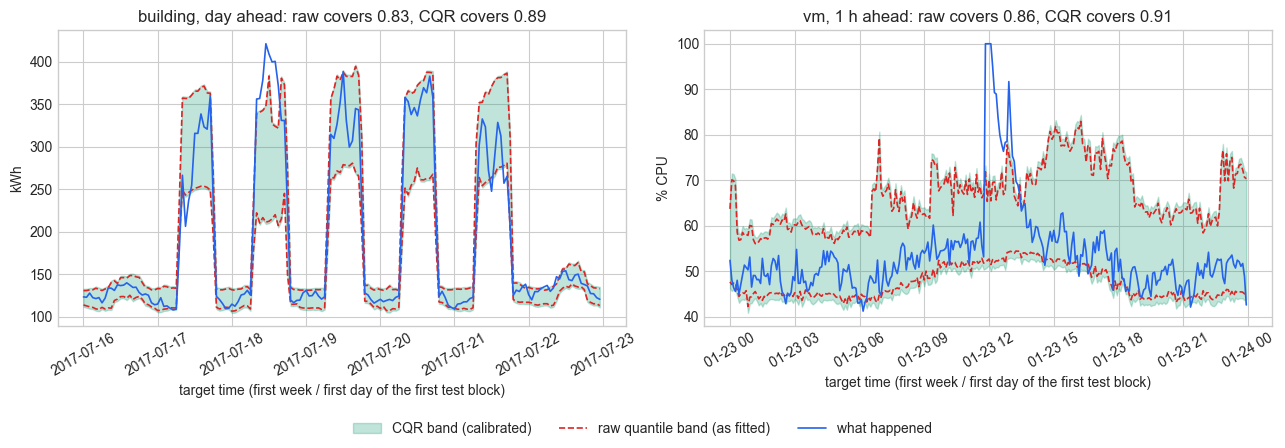

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (fam, h, n_show, unit) in zip(axes, [("building", 24, 24 * 7, "kWh"),
                                             ("vm", 12, 288, "% CPU")]):
    res = RESULTS[(fam, h, "local GBM")]
    part = res[res["block"] == 0].iloc[:n_show]
    t = part["target_time"]
    ax.fill_between(t, part["lo"], part["hi"], color=GREEN, alpha=0.25,
                    label="CQR band (calibrated)")
    ax.plot(t, part["raw_lo"], color=RED, linestyle="--", linewidth=1.2,
            label="raw quantile band (as fitted)")
    ax.plot(t, part["raw_hi"], color=RED, linestyle="--", linewidth=1.2)
    ax.plot(t, part["y"], color=BLUE, linewidth=1.2, label="what happened")
    raw_cov = np.mean((part["y"] >= part["raw_lo"]) & (part["y"] <= part["raw_hi"]))
    cqr_cov = np.mean((part["y"] >= part["lo"]) & (part["y"] <= part["hi"]))
    ax.set_title(f"{fam}, {HORIZON_NAME[(fam, h)]}: raw covers {raw_cov:.2f}, "
                 f"CQR covers {cqr_cov:.2f}")
    print(f"{fam}, {HORIZON_NAME[(fam, h)]}, first test block: q_hat = {part['q_hat'].iloc[0]:+.2f} "
          f"{unit} on each edge; raw width {np.mean(part['raw_hi'] - part['raw_lo']):.1f}, "
          f"CQR width {np.mean(part['hi'] - part['lo']):.1f}; readings covered {raw_cov * len(part):.0f} "
          f"of {len(part)} raw, {cqr_cov * len(part):.0f} with CQR")
    ax.set_xlabel("target time (first week / first day of the first test block)")
    ax.set_ylabel(unit)
    ax.tick_params(axis="x", rotation=30)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

The left panel is the first test week of the building's day-ahead forecast. The red dashed
raw edges and the green CQR band nearly coincide - in this block `q_hat` is +2.11 kWh per
edge, widening the band from 52.4 to 56.6 kWh on average - and yet coverage over the week
moves from 0.83 to 0.89. Many of the raw band's misses were near misses: two kWh per edge
recovers nine of the week's 168 hours (140 covered raw, 149 with CQR). The right panel is the VM's first test
day at 1 h ahead: `q_hat` is +1.41 % CPU, the band widens from 18.8 to 21.7, and the
burst near 12:00 escapes both bands anyway. No band calibrated at 90% should catch every
burst - one reading in ten is allowed out - and a burst that starts after the origin is
unforecastable by any method at any price. CQR does not make the forecaster smarter; it
makes the band's promise true.

## 3. A pre-trained model, explained with a stand-in

A **foundation model** for time series (also called a pre-trained forecaster) is a large
network trained once, by somebody else, on many thousands of other series - energy meters,
traffic counts, retail sales, server metrics - and then used **zero-shot** on yours: no
fitting on your series at all, only a look at its recent context at each forecast origin.
Chronos-2, TimesFM, Moirai and Toto are current examples, and several of them emit
quantiles directly. "Zero setup, any series" is precisely this property.

We will not call any of them here: no downloads, no internet, and their interfaces change
faster than notebooks do. Instead we build a **stand-in** that shares the one property the
project's question is about - it never saw our series - and that is small enough to audit:
a **global model**, one quantile GBM per horizon trained once on a corpus of other
buildings (`simulate_building_portfolio`) or other VMs (`simulate_vm_fleet`), then applied
zero-shot to our series and conformalized on our series' own calibration windows. That last
step is the project's actual question - conformal wrappers around pre-trained models - and
it is exactly what we would do with the real thing. Why calibrate on our own windows and
not on the corpus? Notebook 09's lesson (field guide §13): rows of other buildings are not
exchangeable with rows of ours, while our own recent windows are the closest thing we have
to exchangeable with our next block. Be clear about what the stand-in is
not: it shares the defining property, not the architecture, the scale or the corpus of
Chronos-2, TimesFM, Moirai or Toto, and its accuracy below says nothing about theirs. What
transfers is the protocol.

Two design choices make one model serve many series. First, **scale-free inputs**: a small
branch office and a large headquarters do not share a scale, so a model trained on raw kWh
would learn mostly that buildings differ in size. We divide every value feature and the
target by a trailing scale known at the origin - the series' mean over the last 7 days -
predict in those units, and multiply back. Several published foundation models normalize
each input window by its own scale for the same reason. The scale uses only the past, so it
peeks at nothing; a scale computed from the whole series would be notebook 11's
peeking-feature lie in a new costume (field guide §16). Second, a **training cutoff**: the
stand-in's corpus ends before our test period begins, as a real pre-trained model's
training data ends on some date. In this simulation the sites' weather anomalies and bursts
are independent of ours, so calendar overlap would leak little. On real data, buildings in
one city share heat waves, and then both your calibration windows and your test windows
should start after the model's cutoff: a calibration window the model has seen through its
neighbours is flattered just as a test window would be (section 4 shows what flattered
calibration does).

| Aspect | Local GBM (section 2) | Global stand-in (this section) | Real foundation model | Pitfall |
|---|---|---|---|---|
| Trained on | our series' own past | 10 other sites or VMs, once | a large corpus of other series, once | "other" must be checked, not assumed (section 4) |
| Refits during the backtest | before every block, every horizon | none | none | a vendor update silently changes every number; pin the version |
| What it uses from our series | training rows, calibration rows, context | calibration rows and context only | calibration rows and context only | a context window that ends after the origin is a leak your slicing creates |
| Scale handling | learns our kWh directly | divides by a trailing 7-day mean | model-specific normalization | full-series normalization peeks (field guide §16) |
| Are its raw quantiles calibrated? | no (section 2) | no (below) | not guaranteed | shipping raw quantiles (field guide §2) |
| Coverage guarantee comes from | the CQR step | the CQR step | the CQR step | none of the three earns it alone |

The **interface contract** is all a real model must satisfy for every later line of this
notebook to run unchanged. Display-only - this cell does not execute:

```python
def forecast_quantiles(context, horizon):
    """What this notebook needs from ANY forecaster, pre-trained or not.

    context: the series up to and including the forecast origin - nothing later.
    horizon: how many steps ahead.
    Returns three numbers for the value at origin + horizon: q05, q50, q95.
    """
```

Our stand-in meets it in vectorized form: `zero_shot_quantiles` returns the three numbers
for every origin at once. To wrap a real model, replace that one function with a loop over
origins that hands each origin's context window to the model and collects its 5%, 50% and
95% quantiles; `collect_quantiles`, `conformalize` and the benchmark table do not change.
If a model's quantile grid lacks 0.05 and 0.95, take the nearest levels it offers (say 0.1
and 0.9): CQR's calibration step repairs the level, at the price of a band whose shape was
learned for a different level.

In [8]:
VALUE_FEATURES = ["last_value", "mean_last_day", "same_time_yesterday",
                  "same_time_last_week", "median_14d_same_time"]


def scale_free_table(y, h, period, exog=None):
    """make_direct_table, then divide every value feature and the target by a trailing scale.

    The scale is the series' mean over the 7 days up to and including the origin - known
    when the forecast is issued, so dividing by it peeks at nothing. After the division a
    small branch office and a large headquarters speak the same language ('about 1.3 times
    my usual level'), which is what lets one model serve many series. Returns the rescaled
    table and the scale, so predictions can be multiplied back to kWh or % CPU.
    """
    tab = make_direct_table(y, h, period, exog=exog)
    scale = y.rolling(7 * period).mean().reindex(tab.index).to_numpy()
    scale = np.maximum(scale, 1.0)   # guard: a near-idle VM would otherwise divide by ~0
    out = tab.copy()
    for col in VALUE_FEATURES + ["target"]:
        out[col] = out[col] / scale
    return out, scale


# The "vendor's" pre-training corpus: other sites, other machines, never our two series.
# Like a real pre-trained model it has a training cutoff, set before our test period starts.
portfolio = simulate_building_portfolio(10, 560, seed=RANDOM_SEED)
fleet = simulate_vm_fleet(10, 22, seed=RANDOM_SEED)
CORPUS = {"building": (portfolio, "load_kwh"), "vm": (fleet, "cpu_pct")}

for fam, (series, col) in CORPUS.items():
    levels = pd.Series({name: df[col].mean() for name, df in series.items()})
    cutoff = max(df.index[-1] for df in series.values())
    first_test = min(protocol.loc[fam, "first_test_target"])
    assert cutoff < first_test, "the pre-training corpus must end before our test period"
    # Block 1's calibration window starts BEFORE the cutoff - harmless here (the corpus
    # never contains our series), worth avoiding on real data with shared weather.
    first_cal = min(TABLES[(fam, h)]["target_time"].iloc[BLOCKS[(fam, h)][0][1][0]]
                    for h in FAMILIES[fam]["horizons"])
    print(f"{fam}: {len(series)} series, mean level {levels.min():.1f} to {levels.max():.1f} "
          f"(ours: {FAMILIES[fam]['y'].mean():.1f}); corpus ends {cutoff}, "
          f"our first test target {first_test}, block 1 calibrates from {first_cal}")


def pretraining_pool(fam, h, extra=None):
    """Stack the scale-free tables of every corpus series into one training set."""
    series, col = CORPUS[fam]
    has_exog = FAMILIES[fam]["exog"] is not None
    tabs = [scale_free_table(df[col], h, FAMILIES[fam]["period"],
                             exog=df["temp_c"] if has_exog else None)[0]
            for df in series.values()]
    if extra is not None:   # used only in section 4, to commit the overlap leak on purpose
        tabs.append(extra)
    pool = pd.concat(tabs)
    return pool[FAMILIES[fam]["features"]].to_numpy(), pool["target"].to_numpy()


X_pool, y_pool = pretraining_pool("building", 24)
print(f"pre-training rows per building horizon: {len(y_pool):,}; "
      f"scaled target ranges {y_pool.min():.2f} to {y_pool.max():.2f} "
      f"(1.0 = the site's own trailing weekly mean)")

building: 10 series, mean level 157.1 to 327.5 (ours: 199.2); corpus ends 2017-07-13 23:00:00, our first test target 2017-07-16 00:00:00, block 1 calibrates from 2017-06-17 01:00:00
vm: 10 series, mean level 22.0 to 72.9 (ours: 49.5); corpus ends 2019-01-22 23:55:00, our first test target 2019-01-23 00:00:00, block 1 calibrates from 2019-01-21 20:05:00
pre-training rows per building horizon: 131,040; scaled target ranges 0.22 to 3.64 (1.0 = the site's own trailing weekly mean)


The corpus is deliberately unlike our series in level: the ten buildings average 157.1 to
327.5 kWh against our 199.2, the ten VMs 22.0 to 72.9 % CPU against our 49.5. After the
division the pooled building target runs from 0.22 to 3.64 times each site's own trailing
weekly mean, over 131,040 pre-training rows per horizon - about ten times what the local
model trains on in its first block. Both corpora end before our first test target
(2017-07-13 23:00 against 2017-07-16 00:00 for the buildings, 2019-01-22 23:55 against
2019-01-23 00:00 for the VMs), and the assertion in the cell makes that a checked fact
rather than a hope. They do not end before block 1's calibration window, which starts on
2017-06-17 for the building and 2019-01-21 for the VM. That is harmless here, because no
corpus series shares a shock with ours; on real data it is the first thing to fix. What this does not show is whether the corpus is relevant to our
series; only the backtest can say that.

In [9]:
def zero_shot_quantiles(models, fam, h):
    """Our stand-in meets the interface contract: q05, q50, q95 for every origin of the target.

    No fitting on the target happens here - only prediction from the target's own recent
    context (its lags, divided by its own trailing scale), multiplied back afterwards.
    """
    cfg = FAMILIES[fam]
    tab_sf, scale = scale_free_table(cfg["y"], h, cfg["period"], exog=cfg["exog"])
    assert tab_sf.index.equals(TABLES[(fam, h)].index)
    q = np.column_stack([m.predict(tab_sf[cfg["features"]].to_numpy()) for m in models])
    return repair_crossing(q * scale[:, None])


def zero_shot_raw(models, fam, h):
    """Raw quantiles per walk-forward block for a pre-trained model: no refit, ever.

    train_rows are ignored - the model was trained once, elsewhere. Each block only looks
    up the zero-shot quantiles of its calibration and test rows.
    """
    q_all = zero_shot_quantiles(models, fam, h)
    return collect_quantiles(fam, h, lambda train_rows, cal_rows, test_rows:
                             (q_all[cal_rows], q_all[test_rows]))


GLOBAL_MODELS = {}
t_start = time.perf_counter()
for fam, h in TABLES:
    X_pool, y_pool = pretraining_pool(fam, h)
    GLOBAL_MODELS[(fam, h)] = [quantile_gbm(q).fit(X_pool, y_pool) for q in QUANTILES]
    RAW[(fam, h, "global zero-shot")] = zero_shot_raw(GLOBAL_MODELS[(fam, h)], fam, h)
    RESULTS[(fam, h, "global zero-shot")] = conformalize(fam, h, RAW[(fam, h, "global zero-shot")])
print(f"{3 * len(TABLES)} global quantile models, each fitted once, "
      f"in {time.perf_counter() - t_start:.0f} s")

rows = []
for fam, h in TABLES:
    loc, glo = RESULTS[(fam, h, "local GBM")], RESULTS[(fam, h, "global zero-shot")]
    rows.append({"family": fam, "h": h,
                 "local_MAE": scorecard(loc)["MAE"], "global_MAE": scorecard(glo)["MAE"],
                 "global_raw_coverage": scorecard(glo, raw_band=True)["coverage"],
                 "global_CQR_coverage": scorecard(glo)["coverage"],
                 "global_q_hat_mean": glo["q_hat"].mean(),
                 "local_CQR_IS": scorecard(loc)["interval_score"],
                 "global_CQR_IS": scorecard(glo)["interval_score"]})
local_vs_global = pd.DataFrame(rows).set_index(["family", "h"])
local_vs_global.round(3)

15 global quantile models, each fitted once, in 4 s


local_MAE  global_MAE  global_raw_coverage  global_CQR_coverage  global_q_hat_mean  local_CQR_IS  global_CQR_IS
family   h                                                                                                                  
building 1       9.851      10.586                0.884                0.899              0.723        57.388         59.213
         24     15.777      18.823                0.866                0.903              2.496        89.779         99.667
vm       1       2.674       2.698                0.942                0.891             -1.267        23.018         20.850
         12      5.730       5.555                0.944                0.901             -1.897        52.308         47.787
         48      6.063       5.713                0.954                0.914             -2.174        53.352         48.434

Read the coverage columns first, because they hold the notebook's most useful surprise. On
the building the zero-shot raw band is too narrow (0.884 and 0.866), as the local one was.
On the VM it is too WIDE: 0.942, 0.944 and 0.954. A model trained on ten other machines
has learned the fleet's uncertainty, and our VM, relative to its own level, is evidently
calmer than the fleet it learned from. CQR does not care which way the raw band is wrong:
the mean `q_hat` comes out negative on all three VM horizons (-1.267, -1.897 and -2.174 %
CPU), the band shrinks, and coverage lands at 0.891, 0.901 and 0.914. This is notebook 05's thermostat,
not a safety margin, and it is the strongest argument for wrapping a pre-trained model:
its raw quantiles describe somebody else's series. (The 0.914 at 4 hours errs on the safe
side; four calibration windows of one day each are a small sample, and field guide §4's
lottery is the first suspect.)

Accuracy splits by family. On the building, the global model loses to the local one at
both horizons: MAE 10.586 against 9.851 kWh at 1 h, 18.823 against 15.777 at day ahead,
interval score 59.213 against 57.388 and 99.667 against 89.779. Seventeen months or more
of our own meter beat ten other meters, plausibly because the physics is site-specific:
every building in the portfolio has its own HVAC sensitivity and occupancy profile, and
only our own history teaches ours. On the VM, the global model wins every interval score
(20.850 against 23.018, 47.787 against 52.308, 48.434 against 53.352) and two of three
MAEs: the local model trains on about 2,000 rows - seven days - in its first block, and
ten machines' worth of bursts teach more about bursts than one machine's week does. The
data scientist and the vendor each win a family - which is exactly why the table must be
per family.

## 4. Pre-training overlap, committed live

The vendor's deck will show a zero-shot benchmark. Ask one question before reading it: was
the benchmark series in the pre-training corpus? Foundation models are trained on large
collections of public datasets, and the public datasets a project like ours would benchmark
on - Building Data Genome 2, the Azure traces - are exactly the kind of data such
collections contain. If the test series was in the corpus, "zero-shot" is a misnomer: the
model has seen the very hours it is graded on. That is **pre-training overlap**, and it is
leakage in notebook 11's sense, one level up (field guide §23).

We commit it live. The stand-in is retrained on a corpus that INCLUDES our series - its
whole history, test period and all - and the identical zero-shot plus CQR backtest is
rerun. Two horizons, building day ahead and VM 1 h, with the stand-in as is. Then the VM
horizon once more with `quantile_gbm_large`, a higher-capacity cousin, because a real
foundation model has orders of magnitude more capacity to memorize than 60 small trees, and
memorization is what the leak feeds on.

In [10]:
def quantile_gbm_large(q, seed=20260707):
    """A higher-capacity cousin of quantile_gbm, used ONLY in this section.

    200 trees of up to 63 leaves, leaves as small as 5 rows (quantile_gbm: 60 trees of 15
    leaves, scikit-learn's default 20-row minimum). More capacity means more room to
    memorize - which is what a leak feeds on.
    """
    return HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=200,
                                         learning_rate=0.15, max_leaf_nodes=63,
                                         min_samples_leaf=5, early_stopping=False,
                                         random_state=seed)


OVERLAP_RUNS = [("building", 24, "small", quantile_gbm),
                ("vm", 12, "small", quantile_gbm),
                ("vm", 12, "large", quantile_gbm_large)]
rows = []
t_start = time.perf_counter()
for fam, h, size, make_model in OVERLAP_RUNS:
    cfg = FAMILIES[fam]
    # The leak: OUR series - its whole history, test period included - joins the corpus.
    target_sf, _ = scale_free_table(cfg["y"], h, cfg["period"], exog=cfg["exog"])
    for pool, extra in [("honest", None), ("overlap", target_sf)]:
        if size == "small" and pool == "honest":
            res = RESULTS[(fam, h, "global zero-shot")]   # the section 3 model, reused
        else:
            X_pool, y_pool = pretraining_pool(fam, h, extra=extra)
            models = [make_model(q).fit(X_pool, y_pool) for q in QUANTILES]
            res = conformalize(fam, h, zero_shot_raw(models, fam, h))
        rows.append({"family": fam, "h": h, "model_size": size,
                     "pool": pool, **scorecard(res)})
print(f"overlap experiments refitted in {time.perf_counter() - t_start:.0f} s")
overlap = pd.DataFrame(rows).set_index(["family", "h", "model_size", "pool"])
honest_is = overlap.xs("honest", level="pool")["interval_score"]
overlap["IS_flattery_pct"] = [
    100 * (1 - row["interval_score"] / honest_is.loc[key[:3]])
    for key, row in overlap.iterrows()]
overlap.round(3)

overlap experiments refitted in 8 s


MAE  coverage   width  interval_score  IS_flattery_pct
family   h  model_size pool                                                              
building 24 small      honest   18.823     0.903  80.213          99.667            0.000
                       overlap  18.166     0.901  75.129          93.696            5.991
vm       12 small      honest    5.555     0.901  36.610          47.787            0.000
                       overlap   5.339     0.894  29.707          39.515           17.311
            large      honest    5.817     0.909  30.960          49.779            0.000
                       overlap   4.536     0.894  22.640          26.234           47.300

The leak is real, and its size depends on two things we can name. With the small stand-in
on the building, including our series flatters the day-ahead interval score by 5.991%
(99.667 down to 93.696) and the MAE from 18.823 to 18.166 kWh: our series is one of eleven
in the pool, a 60-tree model can memorize little of it, and - plausibly - the building's
regular daily cycle leaves little that is worth memorizing. On the VM the same small model
is flattered by 17.311% (47.787 down to 39.515): bursts are the unpredictable part of a CPU
series, and a model that has seen the test period's bursts has, in effect, been told when
they happen. The leaky small model would now beat every honest method at VM 1 h in the
benchmark table of section 6.

The large model is the warning. Honestly evaluated, extra capacity HURTS: its interval
score is 49.779 against the small model's 47.787, and its MAE 5.817 against 5.555 - more
trees, more overfitting to the corpus. With the overlap, the same large model scores 26.234,
a 47.300% flattery, and its MAE drops to 4.536. Under leakage, more capacity looks like
progress; that is how an overlap survives a model-selection meeting.

One more subtlety, the one that makes this leak dangerous: coverage did not move. The
leaky rows cover 0.901, 0.894 and 0.894, because the calibration windows were in the
corpus too and were flattered just as much as the test rows. CQR keeps its promise on the
backtest and the backtest still lies - about MAE, width and interval score, the very
numbers that pick the winner. No coverage check catches pre-training overlap; only an
audit does. The practical rule: check the pre-training data lists published with the
model (model cards, papers); prefer series released after the model's training cutoff, or
series you can show were excluded; and when you can do neither, report the overlap next to
the score.

## 5. An ensemble

The section 3 table hinted that the two models are good at different things: the local one
knows our building's own physics, the global one has seen more bursts than our VM ever
produced. The cheapest way to use both is **quantile averaging**: average the two
forecasters' q05 with q05, q50 with q50 and q95 with q95, row by row, then wrap the averaged
band with CQR like any other forecaster. (Averaging quantiles level by level is sometimes
called Vincentization in the forecast-combination literature.) No theory about the members
is needed - the conformal step calibrates the average directly - and because both members'
raw quantiles are already stored per block, the ensemble costs no fitting at all.

In [11]:
rows = []
for fam, h in TABLES:
    # Average the two forecasters' quantiles level by level (q05 with q05, ...), block by
    # block. Both members are already repaired, so the average cannot cross either.
    RAW[(fam, h, "ensemble")] = [
        ((loc_cal + glo_cal) / 2, (loc_test + glo_test) / 2)
        for (loc_cal, loc_test), (glo_cal, glo_test)
        in zip(RAW[(fam, h, "local GBM")], RAW[(fam, h, "global zero-shot")])]
    RESULTS[(fam, h, "ensemble")] = conformalize(fam, h, RAW[(fam, h, "ensemble")])
    cards = {m: scorecard(RESULTS[(fam, h, m)]) for m in ["local GBM", "global zero-shot", "ensemble"]}
    rows.append({"family": fam, "h": h,
                 "MAE_local": cards["local GBM"]["MAE"],
                 "MAE_global": cards["global zero-shot"]["MAE"],
                 "MAE_ensemble": cards["ensemble"]["MAE"],
                 "IS_local": cards["local GBM"]["interval_score"],
                 "IS_global": cards["global zero-shot"]["interval_score"],
                 "IS_ensemble": cards["ensemble"]["interval_score"],
                 "ensemble_coverage": cards["ensemble"]["coverage"]})
ensemble_check = pd.DataFrame(rows).set_index(["family", "h"])
ensemble_check.round(3)

MAE_local  MAE_global  MAE_ensemble  IS_local  IS_global  IS_ensemble  ensemble_coverage
family   h                                                                                           
building 1       9.851      10.586         9.872    57.388     59.213       56.080              0.900
         24     15.777      18.823        16.735    89.779     99.667       90.911              0.898
vm       1       2.674       2.698         2.624    23.018     20.850       21.257              0.892
         12      5.730       5.555         5.487    52.308     47.787       46.378              0.905
         48      6.063       5.713         5.658    53.352     48.434       46.697              0.913

The ensemble is never the worst member and often the best. It has the lowest interval
score in three of five rows: building 1 h (56.080 against 57.388 local and 59.213 global),
VM 1 h (46.378 against 52.308 and 47.787) and VM 4 h (46.697 against 53.352 and 48.434).
Where one member is clearly stronger it lands in between, close to the stronger one:
building day ahead 90.911 against the local model's 89.779, VM 5 minutes 21.257 against the
global model's 20.850. It also has the lowest MAE on the VM at every horizon (2.624, 5.487,
5.658). Coverage stays in the lottery band (0.892 to 0.913), as it must: the guarantee
belongs to the wrapper, not to the members.

What it does not mean: an ensemble's win is not free. It doubles the forecasting
pipeline - a local model to refit and a pre-trained model to audit - for gains of roughly
2% to 4% in interval score over the better member, where it wins at all. Whether that is
worth it is a cost question, and section 7 asks it.

## 6. The benchmark table

Now the artefact the project needs: one tidy table, family x horizon x method, with MAE,
coverage, width and interval score, every method scored on exactly the same test origins of
the same walk-forward blocks (the assertion in the cell checks it). The layout is
notebook 11's - index `family`, `h`, `method`; columns `point`, `MAE`, `coverage`, `width`,
`interval_score` - and its two band rows are recomputed here with the same code path, so
they match it exactly. Seven contenders, rules first, and one stress test:

- "percentile reference band" - notebook 10's reference band, the 5th to 95th percentile
  of the same time of day over the last 14 days, quoted as is; point forecast = the 14-day
  median.
- "percentile reference band + CQR" - the same three numbers treated as a forecaster's
  q05, q50 and q95 and wrapped. It separates the wrapper's contribution from the model's:
  the same calibration step as the models, with rule-quality inputs.
- "best simple rule + absolute-residual band" - the best of the four simple rules, chosen
  in advance (below), in notebook 02's band (CQR on a zero-width band, section 1).
- "median GBM + absolute-residual band" - notebook 11's model row: the local GBM's median
  in the same constant-width band. Next to the row below it, it isolates what CQR's shape
  adds to the same point forecast.
- "local GBM + CQR", "global zero-shot + CQR" and "ensemble + CQR" - sections 2, 3 and 5.
- "best rule in hindsight (stress test)" - the rule with the lowest MAE on the test rows
  themselves, in the same band. Not a contender, and not ranked.

One trap deserves a sentence before the code. The best simple rule is chosen IN ADVANCE,
exactly as notebook 11's audition chooses it: the rule with the lowest MAE on every usable
row before the first test row. That is the only choice a team could have deployed. Picking
the rule by its MAE on the test rows would be notebook 11's lie number three in a new
costume - choosing on the period you then report - and it flatters the rule (field guide
§17). The hindsight pick is still worth seeing, as a stress test of how good a simple rule
can get, so it gets its own clearly labelled row. `IS_rank` ranks the seven contenders
within each family and horizon by interval score; 1 is the winner.

In [12]:
# The simple rules' champion per family and horizon, chosen IN ADVANCE with notebook 11's
# audition (copied verbatim below), the only choice a deployed team could have made (field
# guide §17). The rule that wins on the test rows themselves is kept as a stress test,
# labelled as such, and is not ranked.
def audition_simple_rules(tab, first_test_row, h, rules=BASELINES):
    """Choose the simple rule IN ADVANCE, the way a deployment would have to.

    Scores every rule on the pre-test history: the usable rows before `first_test_row`
    whose targets are already observed at that row's origin (rows 0 .. first_test_row - h,
    the same purge as the calibration window). The rule with the lowest MAE there is frozen
    for the whole test period; ties go to the rule listed first in `rules`.
    Returns (chosen rule, {rule: pre-test MAE}).
    """
    history = tab.iloc[:first_test_row - h + 1]
    mae = {rule: float(np.mean(np.abs(history["target"] - history[rule]))) for rule in rules}
    return min(mae, key=mae.get), mae


TEST_ROWS = {key: np.concatenate([te for _, _, te in BLOCKS[key]]) for key in TABLES}
champion, hindsight = {}, {}
for key, tab in TABLES.items():
    champion[key], _ = audition_simple_rules(tab, TEST_ROWS[key][0], key[1])
    during = tab.iloc[TEST_ROWS[key]]
    hindsight[key] = min(BASELINES, key=lambda r: np.mean(np.abs(during["target"] - during[r])))
    print(f"{key[0]:>8}, h = {key[1]:>2}: chosen in advance {champion[key]:<21} "
          f"(best in hindsight: {hindsight[key]})")
STRESS = "best rule in hindsight (stress test)"


def fixed_band_raw(fam, h, lo_col, point_col, hi_col):
    """A rule's raw quantiles straight from table columns: no model, no fitting."""
    q = TABLES[(fam, h)][[lo_col, point_col, hi_col]].to_numpy()
    return collect_quantiles(fam, h, lambda train_rows, cal_rows, test_rows:
                             (q[cal_rows], q[test_rows]))


rows, BENCH_RESULTS = [], {}
for (fam, h), tab in TABLES.items():
    test = tab.iloc[TEST_ROWS[(fam, h)]]
    rule = champion[(fam, h)]
    # The local GBM's median, as a zero-width raw band: no new fits needed.
    q_median = [(q_cal[:, [1, 1, 1]], q_test[:, [1, 1, 1]])
                for q_cal, q_test in RAW[(fam, h, "local GBM")]]
    results = {
        # The reference band of notebook 10, quoted as is - no calibration at all.
        "percentile reference band": pd.DataFrame({
            "y": test["target"], "point": test["median_14d_same_time"],
            "lo": test["p05_14d_same_time"], "hi": test["p95_14d_same_time"]}),
        # The same 14-day percentiles, treated as a forecaster's q05 / q50 / q95 and wrapped.
        "percentile reference band + CQR": conformalize(fam, h, fixed_band_raw(
            fam, h, "p05_14d_same_time", "median_14d_same_time", "p95_14d_same_time")),
        # Absolute-residual split conformal (notebook 02) IS CQR on a zero-width raw band:
        # max(point - y, y - point) = |y - point|, and the band is point -/+ q_hat.
        "best simple rule + absolute-residual band": conformalize(
            fam, h, fixed_band_raw(fam, h, rule, rule, rule)),
        # Notebook 11's model row: the same median GBM, inside the absolute-residual band.
        "median GBM + absolute-residual band": conformalize(fam, h, q_median),
        "local GBM + CQR": RESULTS[(fam, h, "local GBM")],
        "global zero-shot + CQR": RESULTS[(fam, h, "global zero-shot")],
        "ensemble + CQR": RESULTS[(fam, h, "ensemble")],
        STRESS: conformalize(fam, h, fixed_band_raw(
            fam, h, hindsight[(fam, h)], hindsight[(fam, h)], hindsight[(fam, h)])),
    }
    point_name = {"percentile reference band": "median_14d_same_time",
                  "median GBM + absolute-residual band": "median GBM",
                  "percentile reference band + CQR": "median_14d_same_time",
                  "best simple rule + absolute-residual band": rule,
                  "local GBM + CQR": "median GBM", "global zero-shot + CQR": "global q50",
                  "ensemble + CQR": "mean of the two q50", STRESS: hindsight[(fam, h)]}
    for method, res in results.items():
        # Every method is scored on exactly the same test origins, in the same order.
        assert np.allclose(res["y"].to_numpy(), test["target"].to_numpy())
        BENCH_RESULTS[(fam, h, method)] = res
        rows.append({"family": fam, "h": h, "method": method, "point": point_name[method],
                     **band_report(res["y"], res["point"], res["lo"], res["hi"], ALPHA)})

benchmark = pd.DataFrame(rows)
contender = benchmark["method"] != STRESS
benchmark["IS_rank"] = (benchmark[contender].groupby(["family", "h"])["interval_score"]
                        .rank(method="min")).astype("Int64")   # the stress test is not ranked
benchmark = benchmark.set_index(["family", "h", "method"])
benchmark.round(3)

building, h =  1: chosen in advance last_value            (best in hindsight: last_value)
building, h = 24: chosen in advance same_time_last_week   (best in hindsight: same_time_last_week)
      vm, h =  1: chosen in advance last_value            (best in hindsight: last_value)
      vm, h = 12: chosen in advance last_value            (best in hindsight: median_14d_same_time)
      vm, h = 48: chosen in advance same_time_yesterday   (best in hindsight: median_14d_same_time)


point     MAE  coverage    width  interval_score  IS_rank
family   h  method                                                                                                             
building 1  percentile reference band                  median_14d_same_time  40.055     0.802  127.481         168.046        6
            percentile reference band + CQR            median_14d_same_time  40.055     0.892  138.372         163.525        5
            best simple rule + absolute-residual band            last_value  19.633     0.900  148.535         207.639        7
            median GBM + absolute-residual band                  median GBM   9.851     0.897   51.927          81.192        4
            local GBM + CQR                                      median GBM   9.851     0.893   43.960          57.388        2
            global zero-shot + CQR                               global q50  10.586     0.899   47.648          59.213        3
            ensemble + CQR                              mean of the two q50   9.872     0.900   44.936          56.080        1
            best rule in hindsight (stress test)                 last_value  19.633     0.900  148.535         207.639     <NA>
         24 percentile reference band                  median_14d_same_time  40.055     0.802  127.481         168.046        6
            percentile reference band + CQR            median_14d_same_time  40.055     0.893  138.408         163.480        5
            best simple rule + absolute-residual band   same_time_last_week  24.118     0.894  122.689         193.008        7
            median GBM + absolute-residual band                  median GBM  15.777     0.894   84.201         133.798        4
            local GBM + CQR                                      median GBM  15.777     0.898   63.731          89.779        1
            global zero-shot + CQR                               global q50  18.823     0.903   80.213          99.667        3
            ensemble + CQR                              mean of the two q50  16.735     0.898   69.957          90.911        2
            best rule in hindsight (stress test)        same_time_last_week  24.118     0.894  122.689         193.008     <NA>
vm       1  percentile reference band                  median_14d_same_time   5.631     0.829   21.935          53.747        7
            percentile reference band + CQR            median_14d_same_time   5.631     0.881   25.941          52.474        6
            best simple rule + absolute-residual band            last_value   2.849     0.898   10.747          20.999        3
            median GBM + absolute-residual band                  median GBM   2.674     0.899    9.372          19.830        1
            local GBM + CQR                                      median GBM   2.674     0.895   12.961          23.018        5
            global zero-shot + CQR                               global q50   2.698     0.891   10.141          20.850        2
            ensemble + CQR                              mean of the two q50   2.624     0.892   11.293          21.257        4
            best rule in hindsight (stress test)                 last_value   2.849     0.898   10.747          20.999     <NA>
         12 percentile reference band                  median_14d_same_time   5.631     0.829   21.935          53.747        5
            percentile reference band + CQR            median_14d_same_time   5.631     0.885   26.116          52.387        4
            best simple rule + absolute-residual band            last_value   8.226     0.890   44.888          74.480        7
            median GBM + absolute-residual band                  median GBM   5.730     0.900   27.848          56.259        6
            local GBM + CQR                                      median GBM   5.730     0.902   24.657          52.308        3
            global zero-shot + CQR                               global q50   5.555     0.901   36.610

The printout above the table is the first finding. For both building horizons and for the
VM at 5 minutes, foresight and hindsight agree: last value an hour (or five minutes) ahead,
same hour last week a day ahead. For the VM at 1 h and 4 h they do not: the history before
the test period picks last value and same time yesterday, and the test period then
belongs to the 14-day median. Choosing a rule in advance is itself a forecasting problem.

Then read the table by family. On the building, the models win outright. At 1 h the
ensemble ranks first (interval score 56.080), the local GBM with CQR second (57.388); at
day ahead the local GBM with CQR wins (89.779). The best calibrated rule band scores
163.525 at 1 h and 163.480 at day ahead, and the chosen rules' MAEs (19.633 for last
value, 24.118 for same hour last week) are double and one and a half times the median
GBM's (9.851, 15.777). Look also at the "best simple rule" rows: last value is the most
accurate rule at 1 h, yet its band is the worst in the family (width 148.535, interval
score 207.639). A constant-width band has to stretch, all day and all night, to cover the
few hours when occupancy switches on and off (07:00-08:00 and 18:00-19:00), where last
value is badly wrong - notebook 05's one-width-for-every-house problem in time-series form.

The two median-GBM rows answer the question section 2 left open: same point forecast,
two bands. On the building, CQR's band is far cheaper than notebook 11's constant one
(57.388 against 81.192 at 1 h, 89.779 against 133.798 at day ahead) at much the same coverage:
the quantile models learned which hours are hard. On the VM at 1 h and 4 h CQR also wins
(52.308 against 56.259, 53.352 against 56.539). At 5 minutes it loses: the constant band
covers 0.899 with a width of 9.372, CQR covers 0.895 with 12.961, and the constant band
is the best band in that row (19.830). Adaptivity has to be learned, and at 5 minutes on a
week of bursty data the learned shape costs more width than it saves in misses. Keep the
constant band in your table; it is the control that tells you whether CQR earned its keep.

On the VM, the verdict depends on the horizon. At 5 minutes the median GBM's constant band
wins (19.830), the global model with CQR is second (20.850) and last value with its band
third (20.999), while the local GBM with CQR is fifth (23.018). At 1 h and 4 h, the rule
the audition would have deployed is the worst contender in the table: last value scores MAE
8.226 and interval score 74.480 at 1 h, same time yesterday 8.246 and 74.519 at 4 h,
against model MAEs of 5.487 to 6.063 and model interval scores of 46.378 to 56.539. The
stress-test row shows how close the right rule comes: the 14-day median, picked with
hindsight, scores MAE 5.631 at both horizons - level with the models, ahead of all of them
at 4 h (5.631 against 5.658) - with interval scores of 57.038 and 57.338. On cloud series
the right simple rule is strong; finding it in advance is the hard part.

The 14-day median also appears without any selection, as the point of the reference band,
and the wrapper does a lot for that band: CQR lifts its coverage from 0.802 to 0.892 and 0.893 on the
building and from 0.829 to 0.881, 0.885 and 0.889 on the VM. Wrapped, it is the best rule
band at VM 1 h and 4 h (52.387 and 52.932). The ensemble beats it (46.378 and 46.697); the
local GBM's CQR band barely does at 1 h (52.308 against 52.387) and does not at 4 h (53.352
against 52.932). On the VM, the band gain at long horizons comes from the global model's breadth,
not from boosting as such.

What the coverage column does not do is separate anything. Every calibrated row sits
between 0.881 and 0.914; the raw percentile band (0.802, 0.829) is the only row that
breaks its promise, and in four of the five rows it is not even the worst interval
score. Coverage says who kept the promise; the interval score says who kept it cheaply
(field guide §18).

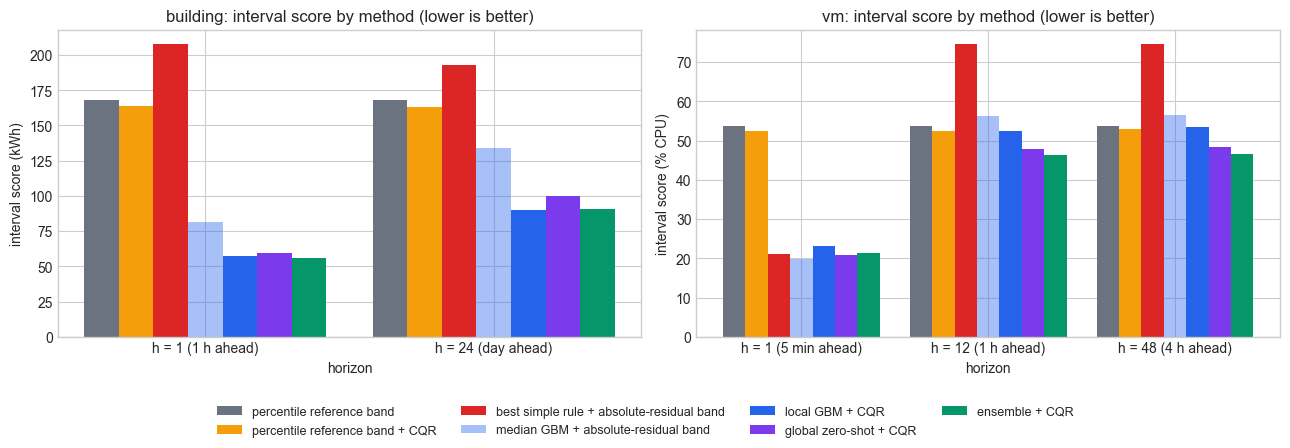

In [13]:
METHODS = [m for m in benchmark.index.get_level_values("method").unique() if m != STRESS]
# Rules in gray / amber / red; the same median GBM in pale blue (constant band) and solid
# blue (CQR band); the global model purple; the ensemble green.
METHOD_STYLE = dict(zip(METHODS, [(GRAY, 1.0), (AMBER, 1.0), (RED, 1.0), (BLUE, 0.4),
                                  (BLUE, 1.0), (PURPLE, 1.0), (GREEN, 1.0)]))
bm = benchmark.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, fam, unit in zip(axes, ["building", "vm"], ["kWh", "% CPU"]):
    part = (bm[bm["family"] == fam]
            .pivot(index="h", columns="method", values="interval_score")
            .loc[list(FAMILIES[fam]["horizons"]), METHODS])
    x = np.arange(len(part))
    bar_width = 0.12
    for i, method in enumerate(METHODS):
        color, alpha = METHOD_STYLE[method]
        ax.bar(x + (i - 3) * bar_width, part[method], bar_width,
               color=color, alpha=alpha, label=method)
    ax.set_xticks(x)
    ax.set_xticklabels([f"h = {h} ({HORIZON_NAME[(fam, h)]})" for h in part.index])
    ax.set_title(f"{fam}: interval score by method (lower is better)")
    ax.set_xlabel("horizon")
    ax.set_ylabel(f"interval score ({unit})")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

The bar chart is the benchmark table at a glance, lower is better; the stress-test row is
left out, since nobody could have deployed it. On the left, the three CQR model bars
(solid blue, purple, green) stand at about a third of the rule bars at 1 h and about half
at day ahead, with the pale blue bar - the same median GBM in notebook 11's constant band -
in between: the model buys most of the gain over the rules, and CQR's shape buys the rest.
On the right the picture changes with the horizon. At 5 minutes every bar except the two
percentile bands is within a few % CPU of the others and the pale blue bar is the shortest.
At 1 h and 4 h the red bar - the rule the audition would have deployed - towers over
everything, the gray and amber percentile bars sit 13 to 16% above the green ensemble bar,
and the pale blue bar is the tallest of the models. The chart does not show the
uncertainty of those VM gaps: eight test days of one machine, four blocks. The decision
table below adds the block count, because an average gain that comes from one lucky block
is not a gain.

## 7. Does it deserve to replace the simple rule?

The head of operations asked who gets the budget, and "the model with the lowest interval
score" is not yet an answer. A model replaces a rule when its gain over the best simple
rule, per horizon, is larger than what it costs to run - and when the gain is consistent
across blocks rather than carried by one. The cell below scores every model band against
two comparators: for MAE, the rule chosen in advance; for the band, the better of the two
calibrated rule bands (the wrapped percentile band or the chosen rule's constant band).
Picking the better rule band on the test rows can only flatter the rules, so the band gains
are, if anything, understated. For every model it reports both gains and the number of
walk-forward blocks in which its band beat the rule band; for the VM's long horizons it
also prints the interval score of each block.

In [14]:
RULE_BANDS = ["percentile reference band + CQR",          # calibrated rule bands only
              "best simple rule + absolute-residual band"]
MODEL_BANDS = ["median GBM + absolute-residual band", "local GBM + CQR",
               "global zero-shot + CQR", "ensemble + CQR"]
SHORT = {"percentile reference band + CQR": "percentile + CQR",
         "best simple rule + absolute-residual band": "rule + abs",
         "median GBM + absolute-residual band": "GBM + abs", "local GBM + CQR": "local + CQR",
         "global zero-shot + CQR": "global + CQR", "ensemble + CQR": "ensemble + CQR"}


def block_scores(res):
    """Interval score of each walk-forward block separately (notebook 11: the spread is information)."""
    return res.groupby("block").apply(
        lambda part: interval_score(part["y"], part["lo"], part["hi"], ALPHA), include_groups=False)


rows = []
for fam, h in TABLES:
    part = bm[(bm["family"] == fam) & (bm["h"] == h)].set_index("method")
    # Comparators: the MAE of the rule chosen in advance, and the better (lower interval
    # score) of the two calibrated rule bands. Picking the better band on the test rows can
    # only flatter the rules, so the model gains below are, if anything, understated.
    rule_mae = part.loc["best simple rule + absolute-residual band", "MAE"]
    rule_band = part.loc[RULE_BANDS, "interval_score"].idxmin()
    rule_blocks = block_scores(BENCH_RESULTS[(fam, h, rule_band)])
    for model in MODEL_BANDS:
        won = block_scores(BENCH_RESULTS[(fam, h, model)]) < rule_blocks
        rows.append({"family": fam, "h": h, "method": SHORT[model],
                     "MAE": part.loc[model, "MAE"],
                     "MAE_gain_pct": 100 * (1 - part.loc[model, "MAE"] / rule_mae),
                     "interval_score": part.loc[model, "interval_score"],
                     "vs_rule_band": SHORT[rule_band],
                     "IS_gain_pct": 100 * (1 - part.loc[model, "interval_score"]
                                           / part.loc[rule_band, "interval_score"]),
                     "blocks_won": f"{won.sum()} of {len(won)}"})
gains = pd.DataFrame(rows).set_index(["family", "h", "method"])

# Where the VM gains live, block by block (notebook 11: the spread is information).
for h in (12, 48):
    per_block = pd.DataFrame({SHORT[m]: block_scores(BENCH_RESULTS[("vm", h, m)])
                              for m in ["percentile reference band + CQR",
                                        "global zero-shot + CQR", "ensemble + CQR"]})
    print(f"VM h = {h}, interval score per block:")
    print(per_block.round(2).to_string(), "\n")
print(f"total notebook runtime: {time.perf_counter() - NOTEBOOK_START:.0f} s")
gains.round(3)

VM h = 12, interval score per block:
       percentile + CQR  global + CQR  ensemble + CQR
block                                                
0                 49.47         46.62           45.77
1                 64.49         48.83           52.23
2                 46.24         44.34           40.19
3                 49.34         51.36           47.33 

VM h = 48, interval score per block:
       percentile + CQR  global + CQR  ensemble + CQR
block                                                
0                 51.44         49.81           46.34
1                 64.49         47.39           52.26
2                 46.07         45.54           42.07
3                 49.72         50.99           46.12 

total notebook runtime: 19 s


MAE  MAE_gain_pct  interval_score      vs_rule_band  IS_gain_pct blocks_won
family   h  method                                                                                        
building 1  GBM + abs        9.851        49.825          81.192  percentile + CQR       50.349     6 of 6
            local + CQR      9.851        49.825          57.388  percentile + CQR       64.906     6 of 6
            global + CQR    10.586        46.082          59.213  percentile + CQR       63.790     6 of 6
            ensemble + CQR   9.872        49.716          56.080  percentile + CQR       65.705     6 of 6
         24 GBM + abs       15.777        34.587         133.798  percentile + CQR       18.157     6 of 6
            local + CQR     15.777        34.587          89.779  percentile + CQR       45.083     6 of 6
            global + CQR    18.823        21.958          99.667  percentile + CQR       39.034     6 of 6
            ensemble + CQR  16.735        30.615          90.911  percentile + CQR       44.390     6 of 6
vm       1  GBM + abs        2.674         6.137          19.830        rule + abs        5.564     4 of 4
            local + CQR      2.674         6.137          23.018        rule + abs       -9.618     1 of 4
            global + CQR     2.698         5.274          20.850        rule + abs        0.709     2 of 4
            ensemble + CQR   2.624         7.878          21.257        rule + abs       -1.232     2 of 4
         12 GBM + abs        5.730        30.345          56.259  percentile + CQR       -7.391     1 of 4
            local + CQR      5.730        30.345          52.308  percentile + CQR        0.151     2 of 4
            global + CQR     5.555        32.474          47.787  percentile + CQR        8.780     3 of 4
            ensemble + CQR   5.487        33.294          46.378  percentile + CQR       11.471     4 of 4
         48 GBM + abs        6.063        26.474          56.539  percentile + CQR       -6.816     1 of 4
            local + CQR      6.063        26.474          53.352  percentile + CQR       -0.794     2 of 4
            global + CQR     5.713        30.718          48.434  percentile + CQR        8.497     3 of 4
            ensemble + CQR   5.658        31.384          46.697  percentile + CQR       11.779     4 of 4

Read the block printout first, because it settles a question the averages cannot. At VM
1 h and 4 h the wrapped percentile band has one bad block - block 1 in the printout, the
second of four, where it scores 64.49 at both horizons. The global model alone takes that
block easily (48.83 and 47.39) but loses block 3 (51.36 against 49.34, 50.99 against
49.72) and wins the other two by 0.5 to 2.9 points, so its average gains of 8.780% and
8.497% (3 of 4 blocks each) lean on one block. The ensemble beats the rule band in all four
blocks at both horizons, by 2.01 to 12.26 points of interval score.

Then the gains table, one recommended method per row:

- **Building.** Every model band beats the rule band in all 6 of 6 blocks at both horizons.
  The local GBM with CQR cuts MAE by 49.825% at 1 h and 34.587% at day ahead and the
  interval score by 64.906% and 45.083%. The ensemble adds less than a point at 1 h
  (65.705%) and does worse at day ahead (44.390%).
- **VM, 5 minutes.** Only the median GBM in the constant band wins clearly: MAE 6.137%
  better, interval score 5.564% better, 4 of 4 blocks. Every CQR variant is no better than
  last value's band (0.709% for the global model, 2 of 4 blocks) or worse (-1.232% for the
  ensemble, -9.618% for the local GBM).
- **VM, 1 h and 4 h.** Against the rule the audition would have deployed, every model's
  point forecast is 26.474% to 33.294% better. Against the best rule band, the ensemble
  gains 11.471% and 11.779% in all four blocks; the global model alone 8.780% and 8.497% in
  three; the local GBM with CQR 0.151% and -0.794%.

| Family and horizon | Recommended method and its own measured gain | What running it costs | Recommendation |
|---|---|---|---|
| Building, 1 h and day ahead | local GBM + CQR: MAE -49.8% / -34.6%, interval score -64.9% / -45.1%, 6 of 6 blocks | refits per block and horizon (3 models each), a weather-forecast feed, coverage and width monitoring | replace the rule with local GBM + CQR; the ensemble does not pay for a second pipeline |
| VM, 5 minutes | median GBM + constant band: MAE -6.1%, interval score -5.6%, 4 of 4 blocks | refits per block and horizon, coverage and width monitoring | a small, consistent gain: run it if 5-minute forecasts drive something expensive, otherwise keep last value; either way keep the constant band, since every CQR variant did worse here |
| VM, 1 h and 4 h, point forecast | any model: MAE -26% to -33% against the rule chosen in advance | refits, or a vendor contract | do not deploy the audition's rule; the 14-day median matches the models (MAE 5.631), but only in hindsight - keep it only if you commit to it in advance on domain grounds, as notebook 10's evidence allows |
| VM, 1 h and 4 h, band | ensemble + CQR: interval score -11.5% / -11.8%, 4 of 4 blocks (global alone: -8.8% / -8.5%, 3 of 4, leaning on one block) | both pipelines, a pre-trained model to host or license, version pinning, the pre-training audit (field guide §23) | pilot the ensemble band on more VMs before committing; do not buy the global model alone on this evidence |
| Every row | the conformal step itself | one corrected quantile per block and horizon | always wrap: it is the cheapest line in the pipeline, and it brought every row of the table to its promised coverage |

The honest summary for the head of operations: facilities' rule should retire for the
buildings. On the VM, the simple rules the team would have picked in advance lose to every
model by roughly 30% at 1 h and 4 h; the 14-day median is the honest exception, but only
for a team that commits to it before the numbers come in. At 5 minutes the model's gain is
real but small. And the vendor's model earns a place in an ensemble pilot for the VM bands,
after the pre-training audit - not the budget on its own.

## 8. Common mistakes to avoid

1. **Shipping raw quantile bands.** The local GBM's raw bands covered 0.752 to 0.875; the
   global model's raw bands covered 0.866 to 0.954 - wrong in both directions, and nothing
   in either fit said so. A quantile head is an opinion until a calibration set the model
   never trained on has graded it (field guide §2).
2. **One correction for every horizon.** The VM's `q_hat` ran from 0.483 to 1.133 % CPU at
   5 minutes and from 2.308 to 6.220 at 4 hours. Calibrate each horizon separately, and
   report each horizon separately (field guide §19).
3. **Quoting a zero-shot score without a pre-training audit.** Putting our own series into
   the corpus flattered the VM interval score by 17.311% with the small stand-in and
   47.300% with the large one, while coverage stayed at 0.894 with both. Coverage cannot
   detect this leak; only the training-data list can (field guide §23).
4. **Declaring a winner on coverage, or on MAE alone.** Every calibrated row of the
   benchmark covered between 0.881 and 0.914; at building 1 h the most accurate rule had
   the worst band (interval score 207.639). Report MAE, coverage, width and interval score
   together (field guide §18).
5. **Choosing the simple rule on the test period.** Before the test, the audition picked last
   value at VM 1 h and same time yesterday at 4 h (MAE 8.226 and 8.246, interval scores
   74.480 and 74.519); the 14-day median, best in hindsight, scored 5.631. Choose the rule on
   data before the test period, show the hindsight pick only as a labelled stress test, and
   say plainly where the model did not win - at VM 5 minutes the best model band beat last
   value's by only 5.564% (field guide §17).
6. **Normalizing with statistics the forecast could not have known.** The stand-in divides
   by a trailing 7-day mean ending at the origin. A scale computed on the full series would
   carry the test period's level into every feature, and it slips past both the time-shuffle
   test and a future-scramble check that merely reorders the future: a reordering leaves the
   mean, median and standard deviation unchanged. The guards are the trailing scale itself,
   a code review of every normalizer, and a future-scramble check that changes the future
   values (field guide §16; notebook 11 runs that check).
7. **Assuming CQR always beats a constant band.** Around the same median GBM, CQR cut the
   building's 1 h interval score from 81.192 to 57.388 but raised the VM's 5-minute one
   from 19.830 to 23.018. An adaptive band has to learn its shape, and the learning can
   fail; keep notebook 11's constant band in the table as the control (field guide §12).
8. **Reading the stand-in's numbers as a verdict on real foundation models.** Our global
   model is 60 small trees trained on ten simulated series. It reproduces the protocol and
   the overlap mechanism, not Chronos-2's or TimesFM's accuracy; run the same table with
   the real model before quoting anything about it.

## 9. What to say in the project report

**Strong version**

> "We compared seven forecast-and-band methods on a walk-forward backtest (six four-week
> blocks for the building, four two-day blocks for the VM); every band except the raw
> reference band was recalibrated per block and per horizon by split conformal (CQR, or its
> absolute-residual special case). Every calibrated method covered between 88.1% and 91.4%
> against a 90% target, so we ranked them by interval score. For the building, a local
> quantile GBM replaced the best simple rule decisively: day-ahead MAE fell from 24.1 to
> 15.8 kWh against same hour last week, and the interval score from 163.5 kWh for the best
> calibrated rule band to 89.8, in all six blocks. For the VM, the rules our own audition
> would have deployed (last value at 1 h, same time yesterday at 4 h) lost to every model by
> 26% to 33% in MAE; the 14-day median matched the models (MAE 5.63), but it was the best
> rule only in hindsight. At 5 minutes the gain was small: the median GBM in a constant band
> beat last value's band by 6% in interval score (19.83 against 21.00), in all four blocks.
> At 1 h and 4 h the best band, an ensemble of the local and pre-trained models, beat the
> best calibrated rule band by 11% and 12% in every block - but on four blocks of a single
> machine. The zero-shot model was a stand-in - a global GBM pre-trained on ten other series
> with a cutoff before our test period. Retraining it with our own series in the corpus
> flattered its VM 1 h interval score by 17% (6% for the building day ahead, 47% for a
> higher-capacity variant) while coverage stayed within a point of 90%, so any vendor's zero-shot result
> must come with a pre-training data audit."

**Weak version**

> "The pre-trained model and the ensemble achieve 90% coverage on all series and horizons
> and outperform the baselines, demonstrating the value of foundation models for
> operational forecasting."

The weak version is true in its first half and meaningless: every wrapped method reached
90%, the rules included, because the wrapper guarantees it. Its second half is false for
the ensemble at VM 5 minutes (21.257 against 20.999), barely true for the pre-trained model
there (20.850), and at VM 4 h true against the rule chosen in advance but not against the
14-day median; and it attributes to foundation models a result obtained with a 60-tree
stand-in, with no mention of overlap. The strong version names the protocol, ranks by the interval score, gives
per-family verdicts including the ones where the model lost, states the evidence's size,
and reports the overlap test.

### The one-line summary

Every forecaster in this notebook - a 14-day percentile table, a rule, a boosted model, a
model trained on other people's meters, an average of two - left the conformal step with
the same promise kept, between 0.881 and 0.914 coverage, including a pre-trained model
whose raw band was too wide and a local one whose raw band was too narrow. What the step
could not do was choose among them: that took the interval score, per family and horizon,
on blocks the models had never seen, against a rule chosen before the test began. It gave
the buildings to the model outright. On the VM the models beat every rule that could have
been picked in advance by about 30% at 1 h and 4 h, only matched on MAE the 14-day median
that hindsight picks, and won by 6% at 5 minutes. The audit of what a "zero-shot" model was
trained on belongs to the same protocol, because a leak flatters exactly the numbers that
pick the winner.

The conformal wrapper makes every forecaster honest; it cannot make any of them good.